In [ ]:
import pandas as pd
from sklearn.model_selection import KFold, train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    PredictionErrorDisplay,
    mean_absolute_error,
    root_mean_squared_error,
    root_mean_squared_log_error,
    r2_score,
)
import seaborn as sb
import matplotlib.pyplot as plt
import numpy as np
import warnings


warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv(
    "data/train.csv", keep_default_na=False, na_values=["NA"] # вторым параметром отключаем чтобы категориальный None считался отдельной категорией, а третим для NA включаем (они будут NaN))
) 
test = pd.read_csv("data/test.csv", keep_default_na=False, na_values=["NA"])

with pd.option_context("display.max_columns", None):
    display(df.head()) # обычный df.head() - не отображает все столбцы

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,None,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,None,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
df.info()
df.describe(include="all")

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
count,1460.000000,1460.000000,1460,1201.000000,1460.000000,1460,91,1460,1460,1460,...,1460.000000,7,281,54,1460.000000,1460.000000,1460.000000,1460,1460,1460.000000
unique,NaN,NaN,5,NaN,NaN,2,2,4,4,2,...,NaN,3,4,4,NaN,NaN,NaN,9,6,NaN
top,NaN,NaN,RL,NaN,NaN,Pave,Grvl,Reg,Lvl,AllPub,...,NaN,Gd,MnPrv,Shed,NaN,NaN,NaN,WD,Normal,NaN
freq,NaN,NaN,1151,NaN,NaN,1454,50,925,1311,1459,...,NaN,3,157,49,NaN,NaN,NaN,1267,1198,NaN
mean,730.500000,56.897260,NaN,70.049958,10516.828082,NaN,NaN,NaN,NaN,NaN,...,2.758904,NaN,NaN,NaN,43.489041,6.321918,2007.815753,NaN,NaN,180921.195890
std,421.610009,42.300571,NaN,24.284752,9981.264932,NaN,NaN,NaN,NaN,NaN,...,40.177307,NaN,NaN,NaN,496.123024,2.703626,1.328095,NaN,NaN,79442.502883
min,1.000000,20.000000,NaN,21.000000,1300.000000,NaN,NaN,NaN,NaN,NaN,...,0.000000,NaN,NaN,NaN,0.000000,1.000000,2006.000000,NaN,NaN,34900.000000
25%,365.750000,20.000000,NaN,59.000000,7553.500000,NaN,NaN,NaN,NaN,NaN,...,0.000000,NaN,NaN,NaN,0.000000,5.000000,2007.000000,NaN,NaN,129975.000000
50%,730.500000,50.000000,NaN,69.000000,9478.500000,NaN,NaN,NaN,NaN,NaN,...,0.000000,NaN,NaN,NaN,0.000000,6.000000,2008.000000,NaN,NaN,163000.000000
75%,1095.250000,70.000000,NaN,80.000000,11601.500000,NaN,NaN,NaN,NaN,NaN,...,0.000000,NaN,NaN,NaN,0.000000,8.000000,2009.000000,NaN,NaN,214000.000000


In [5]:
df.duplicated().sum()

np.int64(0)

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
1%        61815.970000
10%      106475.000000
50%      163000.000000
90%      278000.000000
99%      442567.010000
max      755000.000000
Name: SalePrice, dtype: float64

<Axes: >

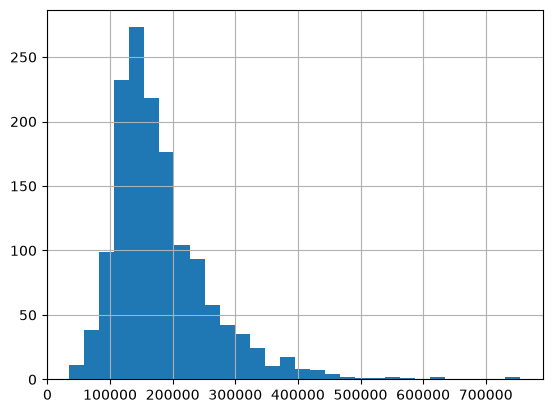

In [6]:
# Краткая сводка цен: минимум, максимум, медиана и квантили
display(df["SalePrice"].describe(percentiles=[0.01, 0.1, 0.5, 0.9, 0.99]))

# Сколько домов попадает в разные диапазоны цен
df["SalePrice"].hist(bins=30)

In [7]:
# Строковые и категориальные столбцы
cat_cols = df.select_dtypes(include=["object", "string", "category"]).columns.tolist()

# Дополнительно проверяем числовые коды, оценки и календарные поля
cols_to_check = cat_cols + [
    "MSSubClass",
    "OverallQual",
    "OverallCond",
    "MoSold",
    "YrSold",
]

rows = []

for column in cols_to_check:
    counts = df[column].value_counts(dropna=False)

    for value, count in counts.items():
        rows.append(
            {
                "feature": column,
                "value": value,
                "count": count,
                "share_pct": round(count / len(df) * 100, 2),
                "expected_val": round(count * 0.2, 1),
            }
        )

frequencies = pd.DataFrame(rows).sort_values("count", ignore_index=True)

with pd.option_context("display.max_rows", None):
    display(frequencies)

,feature,value,count,share_pct,expected_val
0,Exterior1st,AsphShn,1,0.07,0.2
1,OverallCond,1,1,0.07,0.2
2,Condition2,PosA,1,0.07,0.2
3,Condition2,RRAn,1,0.07,0.2
4,Condition2,RRAe,1,0.07,0.2
5,ExterCond,Po,1,0.07,0.2
6,Exterior2nd,CBlock,1,0.07,0.2
7,Exterior2nd,Other,1,0.07,0.2
8,Heating,Floor,1,0.07,0.2
9,HeatingQC,Po,1,0.07,0.2


Для решения о разбиении эта таблица позволяет сказать: «В данных много малочисленных категорий; надёжная отдельная оценка каждой из них невозможна при текущем объёме данных». Она не даёт основания автоматически стратифицировать по всем признакам. Частоты также не показывают, какие категории сильнее влияют на цену и ошибки модели.

# Разбиваем на sets

In [8]:
X_train, X_val, Y_train, Y_val = train_test_split(
    df.drop(columns=["SalePrice", "Id"]),
    df["SalePrice"],
    test_size=0.2,
    random_state=42,
)

# EDA

Автоотчет попробовал уже в самом конце:

In [9]:
%pip install -U skrub

from skrub import TableReport

eda_data = X_train.assign(SalePrice=Y_train)
eda_data["MSSubClass"] = eda_data["MSSubClass"].astype("category")

report = TableReport(
    eda_data,
    title="House Prices — EDA",
    plot_distributions=True,
    compute_associations=True,
)

report.write_html("eda_report.html")
report.open()

Note: you may need to restart the kernel to use updated packages.


Processing column  80 / 80


Вывод
 - оценки качества имеряются единицами, а площади тысячами - надо скейлить (очевидно)
 - У PoolQC 99,5% пропусков, у Alley — 93,7% - надо заполнять
 - Цена имеет длинный правый хвост: медиана $165 тыс., максимум $745 тыс. - пробовать RMSLE
 - Некоторые признаки сильно связаны друг с другом (В отчёте корреляция Пирсона: GarageCars и GarageArea — 0,883; TotalBsmtSF и 1stFlrSF — 0,827). Это показывает частичное дублирование информации - Проверить устойчивость обычной линейной регрессии и сравнить её с Ridge и Lasso.
 - Заметила ллм - Utilities (см. Distributions),  1167 домов имеют AllPub, один — NoSeWa - Можно попробовать выкинуть признак

## Main EDA

<Axes: >

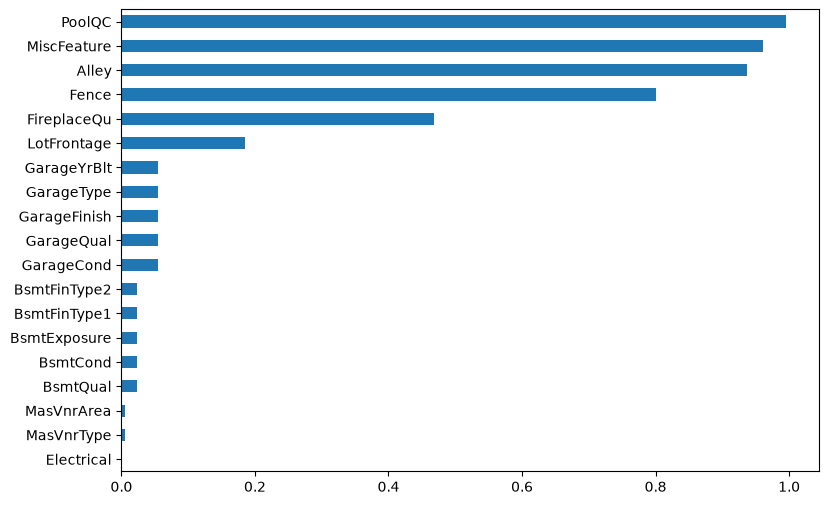

In [10]:
#Доля пропущенных значений у признаков с пропусками
missing = X_train.isna().mean()
missing[missing > 0].sort_values().plot.barh(figsize=(9, 6))

В PoolQC, Alley, Fence и MiscFeature обозначение NA по описанию означает отсутствие соответствующего объекта. Следовательно нужно не заполнять значение самым частотным, а оставить конкретную категорию NA отличную от None, для этого порпваили pd.read_csv() в начале

<Axes: ylabel='SalePrice'>

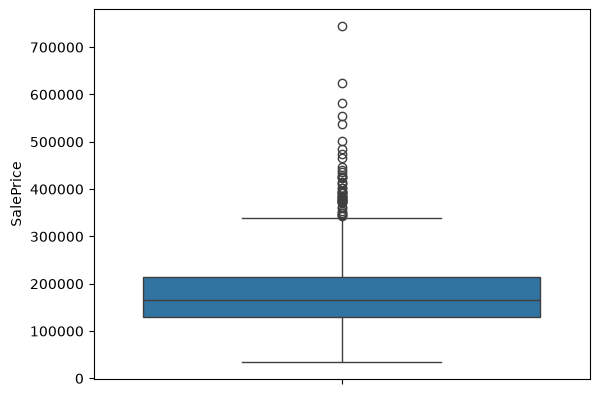

In [11]:
sb.boxplot(data=Y_train)

- Нет повода удалять строки. 
- {пришел к этому в самом конце - не пробовал}: Дорогих домов мало, можно попробовать разделить цены на диапозоны, а затем стратифицировать по этим группам. Но домов дороже 700к всего 2 штуки, не получится на фолдах проверить. Возможно стоило две группы, дороже 400/500к и дешевле. 

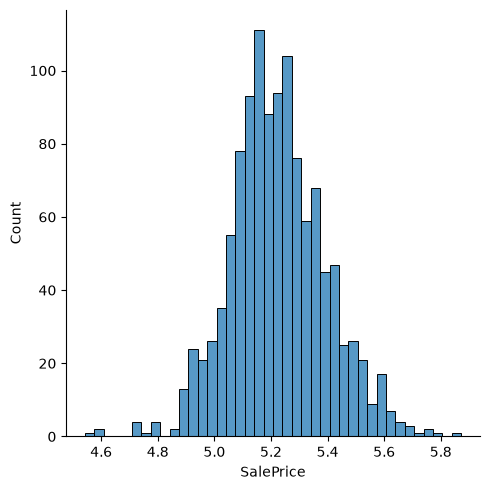

In [12]:
log_result = np.log10(Y_train)
sb.displot(x=log_result, bins=40)

<Axes: xlabel='SalePrice', ylabel='Density'>

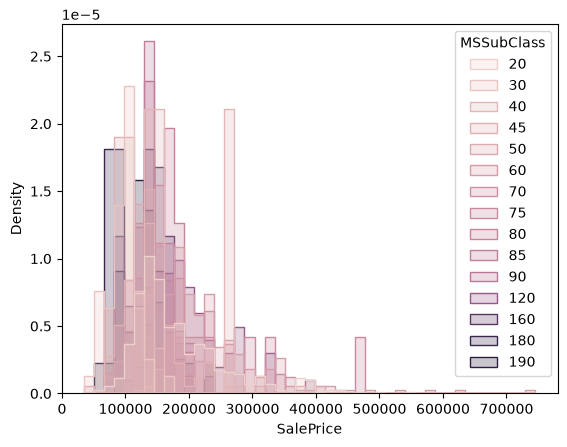

In [13]:
sb.histplot(
    data=X_train,
    x=Y_train,
    hue="MSSubClass",
    stat="density",
    common_norm=False,
    element="step",
)

График оказался перегруженным. Уверенного вывода о различиях между типами домов по нему мы не сделали

<Axes: >

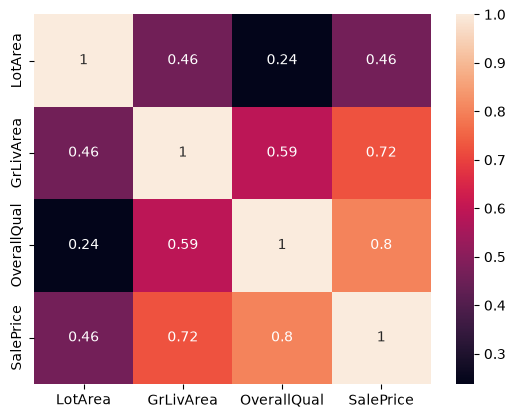

In [14]:
train = X_train.assign(SalePrice=Y_train)

columns = ["LotArea", "GrLivArea", "OverallQual", "SalePrice"]
sb.heatmap(train[columns].corr(method="spearman"), annot=True)

Вывод - добавить регулеризацию в будещем

In [15]:
X_train.select_dtypes("number").nunique().sort_values()

BsmtHalfBath       3
HalfBath           3
Fireplaces         4
KitchenAbvGr       4
FullBath           4
BsmtFullBath       4
GarageCars         5
YrSold             5
PoolArea           7
BedroomAbvGr       8
OverallCond        9
OverallQual       10
TotRmsAbvGrd      12
MoSold            12
MSSubClass        15
3SsnPorch         17
MiscVal           19
LowQualFinSF      20
YearRemodAdd      61
ScreenPorch       66
GarageYrBlt       94
EnclosedPorch     98
LotFrontage      107
YearBuilt        111
BsmtFinSF2       118
OpenPorchSF      188
WoodDeckSF       244
MasVnrArea       286
2ndFlrSF         361
GarageArea       394
BsmtFinSF1       549
TotalBsmtSF      630
1stFlrSF         657
BsmtUnfSF        685
GrLivArea        734
LotArea          890
dtype: int64

In [16]:
def missing_report(data, filename):
    original = pd.read_csv(filename, dtype=str, keep_default_na=False)
    if len(data) != len(original):
        raise ValueError(
            "Передай полный df сразу после загрузки CSV: количество строк различается."
        )

    report = data.isna().sum().to_frame("NaN после чтения")
    for marker in ["NA", "None", "NaN", "nan", "null", "NULL", ""]:
        report[repr(marker)] = original.eq(marker).sum()
    report["Только пробелы"] = original.apply(
        lambda column: column.str.fullmatch(r"\s+")
    ).sum()
    report.index.name = "Признак"
    return report.loc[report.any(axis=1)]


print("train.csv:", len(df), "строк")
display(missing_report(df, "data/train.csv"))

train.csv: 1460 строк


,NaN после чтения,'NA','None','NaN','nan','null','NULL','',Только пробелы
Признак,,,,,,,,,
LotFrontage,259,259,0,0,0,0,0,0,0
Alley,1369,1369,0,0,0,0,0,0,0
MasVnrType,8,8,864,0,0,0,0,0,0
MasVnrArea,8,8,0,0,0,0,0,0,0
BsmtQual,37,37,0,0,0,0,0,0,0
BsmtCond,37,37,0,0,0,0,0,0,0
BsmtExposure,38,38,0,0,0,0,0,0,0
BsmtFinType1,37,37,0,0,0,0,0,0,0
BsmtFinType2,38,38,0,0,0,0,0,0,0


Прикинул что делпать с NA и NONE - оставлять как есть, не заполняя частотным

### Цена и категориальные признаки

Сравним распределения цен по типу зоны и условиям продажи.
Посмотрим на различия между группами и количество домов в каждой из них.

,count,median
MSZoning,,
C (all),4,96500.0
RM,172,124000.0
RH,15,140000.0
RL,924,174700.0
FV,53,207500.0


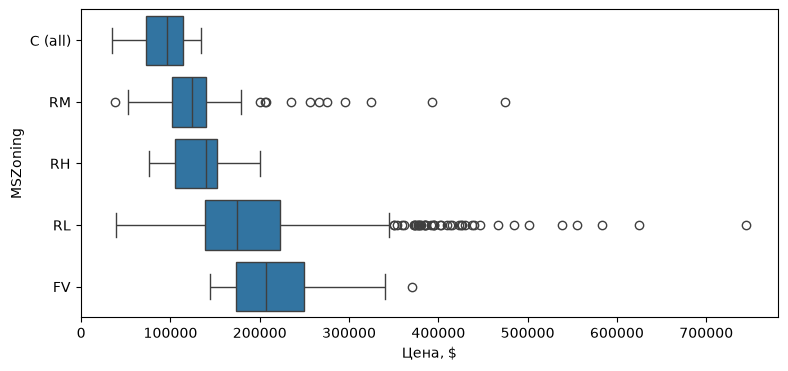

,count,median
SaleCondition,,
AdjLand,4,104000.0
Abnorml,77,138800.0
Family,18,147000.0
Normal,964,162250.0
Alloca,7,179000.0
Partial,98,239399.5


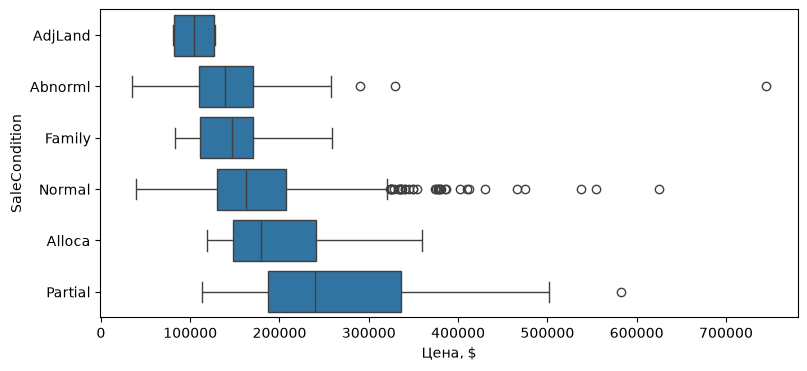

In [17]:
category_data = X_train.assign(SalePrice=Y_train)

for column in ["MSZoning", "SaleCondition"]:
    summary = (
        category_data.groupby(column)["SalePrice"]
        .agg(["count", "median"])
        .sort_values("median")
    )
    display(summary)

    plt.figure(figsize=(9, 4))
    sb.boxplot(
        data=category_data,
        x="SalePrice",
        y=column,
        order=summary.index,
    )
    plt.xlabel("Цена, $")
    plt.show()

Медианная цена в группе FV выше, чем в RM, а в Partial — выше,
чем в Normal. При этом распределения цен перекрываются.

Некоторые группы малочисленны, поэтому выводы по ним ограничены.
Наблюдаемые различия не доказывают причинного влияния категории на цену.

# Подготовка признаков 

In [18]:
def make_preprocess(X):
    numeric_features = X.select_dtypes(include="number").columns.tolist()

    categorical_features = X.select_dtypes(
        include=["object", "string", "category"]
    ).columns.tolist()

    numeric_features.remove("MSSubClass")
    categorical_features.append("MSSubClass")

    preprocess = ColumnTransformer(
        [
            (
                "num",
                Pipeline(
                    [
                        ("Imputer", SimpleImputer(strategy="median")),
                        ("scaler", StandardScaler()),
                    ]
                ),
                numeric_features,
            ),
            (
                "cat",
                Pipeline(
                    [
                        ("imputer", SimpleImputer(strategy="constant", fill_value="NA"),
                        ),
                        ("encoder", OneHotEncoder(handle_unknown="ignore")),
                    ]
                ),
                categorical_features,
            ),
        ]
    )

    return preprocess


preprocess = make_preprocess(X_train)

## Первое сравнение моделей

Используем пять фолдов с перемешиванием и фиксированным seed.
Сначала сравниваем модели по дефолтной метрике: R² — показатель качества всей модели (Для использованных нами регрессоров по умолчанию он)

In [19]:
from sklearn.linear_model import Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor


cv = KFold(n_splits=5, shuffle=True, random_state=0)

baseline = DummyRegressor(strategy="mean")  # .fit(X_train, Y_train)
scores_baseline = cross_val_score(baseline, X_train, Y_train, cv=cv)


model_linear = Pipeline(
    [
        ("prep", preprocess),
        ("model", LinearRegression()),
    ]
)

scores_linear = cross_val_score(model_linear, X_train, Y_train, cv=cv)

scores_ridge = cross_val_score(
    Pipeline([("prep", preprocess), ("model", Ridge(alpha=1.0))]),
    X_train,
    Y_train,
    cv=cv,
)

scores_lasso = cross_val_score(
    Pipeline([("prep", preprocess), ("model", Lasso(alpha=1.0, max_iter=200_000))]),
    X_train,
    Y_train,
    cv=cv,
)

scores_tree = cross_val_score(
    Pipeline(
        [
            ("prep", preprocess),
            ("model", DecisionTreeRegressor()),
        ]
    ),
    X_train,
    Y_train,
    cv=cv,
)

In [20]:
pd.DataFrame(
    {
        "baseline": scores_baseline,
        "linear": scores_linear,
        "ridge": scores_ridge,
        "lasso": scores_lasso,
        "tree": scores_tree,
    }
).agg(["mean", "std"]).T.sort_values("mean", ascending=False)

,mean,std
ridge,0.794923,0.108094
tree,0.624445,0.097097
lasso,0.520331,0.408226
linear,0.060537,1.276537
baseline,-0.007013,0.003948


## Проверяем лин регрессию с логарифмированием

In [21]:
from sklearn.compose import TransformedTargetRegressor

model_log = TransformedTargetRegressor(
    regressor=model_linear,
    func=np.log1p,
    inverse_func=np.expm1,
)

scores_linear_log = cross_val_score(
    model_log,
    X_train,
    Y_train,
    cv=cv,
    scoring="r2",
)

print("С логарифмом:", scores_linear_log.mean())

С логарифмом: 0.036906511043905764


Плохой , вернемся дальше к логарифму еще.

## Второе сравнение моделей

Рассматриваем MAE, RMSE, R² и RMSLE вместе с разбросом результатов между фолдами.

In [22]:
from sklearn.model_selection import cross_validate


def compare_models(X):
    model_list = [
        LinearRegression(),
        TransformedTargetRegressor(
            regressor=LinearRegression(),
            func=np.log1p,
            inverse_func=np.expm1,
        ),
        Ridge(alpha=1.0),
        Lasso(alpha=1.0, max_iter=200_000),
        DecisionTreeRegressor(random_state=42),
    ]

    for model in model_list:
        scores = cross_validate(
            Pipeline([("prep", preprocess), ("model", model)]),
            X,
            Y_train,
            cv=cv,
            scoring={
                "MAE": "neg_mean_absolute_error",
                "RMSE": "neg_root_mean_squared_error",
                "R2": "r2",
                "RMSLE": "neg_root_mean_squared_log_error",
            },
            return_estimator=True,
        )

        print(model)
        display(
            pd.DataFrame(
                {
                    "MAE": -scores["test_MAE"],
                    "RMSE": -scores["test_RMSE"],
                    "R2": scores["test_R2"],
                    "RMSLE": -scores["test_RMSLE"],
                }
            ).agg(["mean", "std"], skipna=False)
        )

        if isinstance(model, DecisionTreeRegressor):
            global tree_depth_mean, tree_objects_in_leaf_mean
            tree_depth_mean = 0
            tree_objects_in_leaf_mean = 0

            for fitted in scores["estimator"]:
                tree = fitted.named_steps["model"]

                tree_depth_mean += tree.get_depth()
                tree_objects_in_leaf_mean += tree.tree_.n_node_samples.min()
            tree_depth_mean = tree_depth_mean / 5
            tree_objects_in_leaf_mean = tree_objects_in_leaf_mean / 5


compare_models(X_train)

/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/model_selection/_validation.py:978: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/metrics/_scorer.py", line 174, in __call__
    score = scorer._score(
        cached_call, estimator, *args, **routed_params.get(name).score
    )
  File "/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/metrics/_scorer.py", line 469, in _score
    return self._sign * self._score_func(y_true, y_pred, **scoring_kwargs)
                        ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/utils/_param_validation.py", line 218, in wrapper
    return func(*args, **kwargs)
  File "/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/metrics/_regression.py

LinearRegression()


/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/model_selection/_validation.py:978: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/metrics/_scorer.py", line 174, in __call__
    score = scorer._score(
        cached_call, estimator, *args, **routed_params.get(name).score
    )
  File "/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/metrics/_scorer.py", line 469, in _score
    return self._sign * self._score_func(y_true, y_pred, **scoring_kwargs)
                        ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/utils/_param_validation.py", line 218, in wrapper
    return func(*args, **kwargs)
  File "/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/metrics/_regression.py

,MAE,RMSE,R2,RMSLE
mean,21032.129314,61607.632200,0.060537,NaN
std,1856.294361,32536.029093,1.276537,NaN


TransformedTargetRegressor(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>,
                           regressor=LinearRegression())


,MAE,RMSE,R2,RMSLE
mean,18448.055920,60844.358925,0.036907,0.167383
std,4737.042333,56306.607581,1.529613,0.040149


... (4 outputs left out)

/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/model_selection/_validation.py:978: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/metrics/_scorer.py", line 174, in __call__
    score = scorer._score(
        cached_call, estimator, *args, **routed_params.get(name).score
    )
  File "/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/metrics/_scorer.py", line 469, in _score
    return self._sign * self._score_func(y_true, y_pred, **scoring_kwargs)
                        ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/utils/_param_validation.py", line 218, in wrapper
    return func(*args, **kwargs)
  File "/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/metrics/_regression.py

,MAE,RMSE,R2,RMSLE
mean,20092.469842,48901.001960,0.520331,NaN
std,1192.361976,14644.267422,0.408226,NaN


DecisionTreeRegressor(random_state=42)


,MAE,RMSE,R2,RMSLE
mean,28474.776116,48276.466343,0.596739,0.216592
std,3091.126878,9937.762386,0.126304,0.019608


## Добавляем дополнительные признаки
Два полиномиальных и один обычный: суммарную площадь жилой части и подвала,
взаимодействие жилой площади с состоянием дома и взаимодействие качества с состоянием. Сравнение проводим на прежних фолдах.

In [23]:
X_train_extra = X_train.copy()

X_train_extra["TotalArea"] = X_train_extra["GrLivArea"] + X_train_extra["TotalBsmtSF"]
X_train_extra["AreaCondition"] = (
    X_train_extra["GrLivArea"] * X_train_extra["OverallCond"]
)
X_train_extra["QualityCondition"] = (
    X_train_extra["OverallQual"] * X_train_extra["OverallCond"]
)

preprocess = make_preprocess(X_train_extra)

compare_models(X_train_extra)


/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/model_selection/_validation.py:978: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/metrics/_scorer.py", line 174, in __call__
    score = scorer._score(
        cached_call, estimator, *args, **routed_params.get(name).score
    )
  File "/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/metrics/_scorer.py", line 469, in _score
    return self._sign * self._score_func(y_true, y_pred, **scoring_kwargs)
                        ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/utils/_param_validation.py", line 218, in wrapper
    return func(*args, **kwargs)
  File "/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/metrics/_regression.py

LinearRegression()


/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/model_selection/_validation.py:978: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/metrics/_scorer.py", line 174, in __call__
    score = scorer._score(
        cached_call, estimator, *args, **routed_params.get(name).score
    )
  File "/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/metrics/_scorer.py", line 469, in _score
    return self._sign * self._score_func(y_true, y_pred, **scoring_kwargs)
                        ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/utils/_param_validation.py", line 218, in wrapper
    return func(*args, **kwargs)
  File "/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/metrics/_regression.py

,MAE,RMSE,R2,RMSLE
mean,21041.661866,61368.662203,0.063357,NaN
std,1772.096518,32681.960314,1.282169,NaN


TransformedTargetRegressor(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>,
                           regressor=LinearRegression())


,MAE,RMSE,R2,RMSLE
mean,18513.465314,60922.781329,0.044926,0.168072
std,4588.451087,55418.731020,1.498125,0.039369


... (4 outputs left out)

/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/model_selection/_validation.py:978: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/metrics/_scorer.py", line 174, in __call__
    score = scorer._score(
        cached_call, estimator, *args, **routed_params.get(name).score
    )
  File "/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/metrics/_scorer.py", line 469, in _score
    return self._sign * self._score_func(y_true, y_pred, **scoring_kwargs)
                        ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/utils/_param_validation.py", line 218, in wrapper
    return func(*args, **kwargs)
  File "/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/metrics/_regression.py

,MAE,RMSE,R2,RMSLE
mean,20040.143151,48291.652541,0.535648,NaN
std,1110.866997,14005.303802,0.383721,NaN


DecisionTreeRegressor(random_state=42)


,MAE,RMSE,R2,RMSLE
mean,25031.597938,38260.354414,0.741660,0.197887
std,1735.086042,5223.000766,0.085656,0.018946


Средняя RMSE до и после добавления признаков (USD):

| Модель | До | После |
| :--- | ---: | ---: |
| Дерево решений | 48 276 | 38 260 |
| Ridge | 33 899 | 33 362 |
| Lasso | 48 901 | 48 292 |

RMSE снизилась у всех трёх моделей. Наибольшее улучшение — у дерева решений.

## Подбор гиперпараметров

Через GridSearchCV подбираем силу регуляризации и ограничения дерева.
Основная метрика выбора — RMSE; остальные метрики используем для сравнения.

In [24]:
from sklearn.model_selection import GridSearchCV

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "RMSLE": "neg_root_mean_squared_log_error",
    "R2": "r2",
}


def tune_model(model, params, X):
    search = GridSearchCV(
        estimator=Pipeline(
            [
                ("prep", preprocess),
                ("model", model),
            ]   
        ),
        param_grid=params,
        cv=cv,
        scoring=scoring,
        refit="RMSE",
    )

    search.fit(X, Y_train)
    return search


search_ridge = tune_model(
    Ridge(),
    {"model__alpha": [0.1, 1, 10, 100, 1000]},
    X_train_extra,
)
print("Ridge:", search_ridge.best_params_, "CV RMSE:", -search_ridge.best_score_)

search_lasso = tune_model(
    Lasso(max_iter=200_000),
    {"model__alpha": [0.1, 1, 10, 100, 1000]},
    X_train_extra,
)
print("Lasso:", search_lasso.best_params_, "CV RMSE:", -search_lasso.best_score_)


search_three = tune_model(
    DecisionTreeRegressor(),
    {
        "model__max_depth": [
            round(tree_depth_mean) - 2,
            round(tree_depth_mean) - 1,
            round(tree_depth_mean),
        ],
        "model__min_samples_leaf": [
            round(tree_objects_in_leaf_mean),
            round(tree_objects_in_leaf_mean) + 10,
        ],
    },
    X_train_extra,
)

print(type(DecisionTreeRegressor()).__name__)
print("Лучшие параметры:", search_three.best_params_)
print("Среднее CV RMSE:", -search_three.best_score_)


/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/model_selection/_validation.py:978: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/metrics/_scorer.py", line 174, in __call__
    score = scorer._score(
        cached_call, estimator, *args, **routed_params.get(name).score
    )
  File "/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/metrics/_scorer.py", line 469, in _score
    return self._sign * self._score_func(y_true, y_pred, **scoring_kwargs)
                        ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/utils/_param_validation.py", line 218, in wrapper
    return func(*args, **kwargs)
  File "/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/metrics/_regression.py

Ridge: {'model__alpha': 10} CV RMSE: 31093.36269351611


/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/linear_model/_coordinate_descent.py:786: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.089750e+10, tolerance: 5.956e+08
  model = cd_fast.sparse_enet_coordinate_descent(
/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/linear_model/_coordinate_descent.py:786: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.944276e+10, tolerance: 5.517e+08
  model = cd_fast.sparse_enet_coordinate_descent(
/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/model_selection/_validation.py:978: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent

Lasso: {'model__alpha': 100} CV RMSE: 30981.524837579094
DecisionTreeRegressor
Лучшие параметры: {'model__max_depth': 21, 'model__min_samples_leaf': 11}
Среднее CV RMSE: 35791.7591963227


In [25]:
search_three_wide = tune_model(
    DecisionTreeRegressor(random_state=42),
    {
        "model__max_depth": [5, 8, 12, 21, None],
        "model__min_samples_leaf": [1, 5, 11, 20, 40],
    },
    X_train_extra,
)

print("Лучшие параметры:", search_three_wide.best_params_)
print("Среднее CV RMSE:", -search_three_wide.best_score_)

Лучшие параметры: {'model__max_depth': 8, 'model__min_samples_leaf': 5}
Среднее CV RMSE: 35676.4428493454


Дополнительно проверяем Ridge и Lasso с преобразованием целевой цены
через `log1p`.

In [26]:
search_ridge_log = tune_model(
    TransformedTargetRegressor(
        regressor=Ridge(),
        func=np.log1p,
        inverse_func=np.expm1,
    ),
    {"model__regressor__alpha": [0.1, 1, 10, 100, 1000]},
    X_train_extra,
)

search_lasso_log = tune_model(
    TransformedTargetRegressor(
        regressor=Lasso(max_iter=200_000),
        func=np.log1p,
        inverse_func=np.expm1,
    ),
    {"model__regressor__alpha": [0.0001, 0.001, 0.01]},
    X_train_extra,
)

In [27]:
# Лучшие по CV RMSE настройки всех пяти вариантов.
results = pd.DataFrame(
    {
        "Ridge": pd.DataFrame(search_ridge.cv_results_).loc[search_ridge.best_index_],
        "Lasso": pd.DataFrame(search_lasso.cv_results_).loc[search_lasso.best_index_],
        "Ridge + log": pd.DataFrame(search_ridge_log.cv_results_).loc[
            search_ridge_log.best_index_
        ],
        "Lasso + log": pd.DataFrame(search_lasso_log.cv_results_).loc[
            search_lasso_log.best_index_
        ],
        "Tree": pd.DataFrame(search_three_wide.cv_results_).loc[
            search_three_wide.best_index_
        ],
    }
).T

results = results.reindex(columns=[
    "params", "mean_test_MAE", "std_test_MAE",
    "mean_test_RMSE", "std_test_RMSE",
    "mean_test_RMSLE", "std_test_RMSLE",
    "mean_test_R2", "std_test_R2", "mean_fit_time", "std_fit_time",
])
results.columns = [
    "Параметры", "MAE", "MAE std", "RMSE", "RMSE std",
    "RMSLE", "RMSLE std", "R2", "R2 std",
    "Обучение, с", "Обучение std, с",
]
results[["MAE", "RMSE", "RMSLE"]] = -results[["MAE", "RMSE", "RMSLE"]].astype(float)
with pd.option_context("display.max_columns", None, "display.max_colwidth", None):
    display(results)

,Параметры,MAE,MAE std,RMSE,RMSE std,RMSLE,RMSLE std,R2,R2 std,"Обучение, с","Обучение std, с"
Ridge,{'model__alpha': 10},18104.948086,1872.479299,31093.362694,9611.281251,0.153157,0.01528,0.825115,0.095363,0.020778,0.000244
Lasso,{'model__alpha': 100},16636.164352,2333.167999,30981.524838,10311.342281,0.139171,0.020752,0.8251,0.099824,0.145297,0.023434
Ridge + log,{'model__regressor__alpha': 10},16936.274838,2896.136865,43265.310970,32689.469521,0.140575,0.034521,0.547005,0.611731,0.020875,0.000207
Lasso + log,{'model__regressor__alpha': 0.001},16664.483511,3305.626748,45770.307758,37133.101073,0.139432,0.037246,0.465299,0.747399,0.052474,0.006109
Tree,"{'model__max_depth': 8, 'model__min_samples_leaf': 5}",23185.939003,2123.940893,35676.442849,7453.922454,0.179386,0.022165,0.774207,0.087202,0.028161,0.002055


## Выбор модели и финальная проверка

Минимальную среднюю CV RMSE показал Lasso с `alpha=100`. Его `best_estimator_` уже переобучен на всей обучающей
выборке после подбора параметров. 

In [28]:
X_val_extra = X_val.copy()

X_val_extra["TotalArea"] = (
    X_val_extra["GrLivArea"] + X_val_extra["TotalBsmtSF"]
)
X_val_extra["AreaCondition"] = (
    X_val_extra["GrLivArea"] * X_val_extra["OverallCond"]
)
X_val_extra["QualityCondition"] = (
    X_val_extra["OverallQual"] * X_val_extra["OverallCond"]
)

final_model = search_lasso.best_estimator_
Y_pred = final_model.predict(X_val_extra)

residuals = Y_val - Y_pred

print("MAE:", mean_absolute_error(Y_val, Y_pred))
print("RMSE:", root_mean_squared_error(Y_val, Y_pred))
print("RMSLE:", root_mean_squared_log_error(Y_val, Y_pred))
print("R²:", r2_score(Y_val, Y_pred))

MAE: 17161.14877160682
RMSE: 28359.10980773947
RMSLE: 0.1462814420146376
R²: 0.895149295171586


## Анализ ошибок

Сравниваем истинные и предсказанные цены, строим распределение остатков
и зависимость остатков от прогнозов.

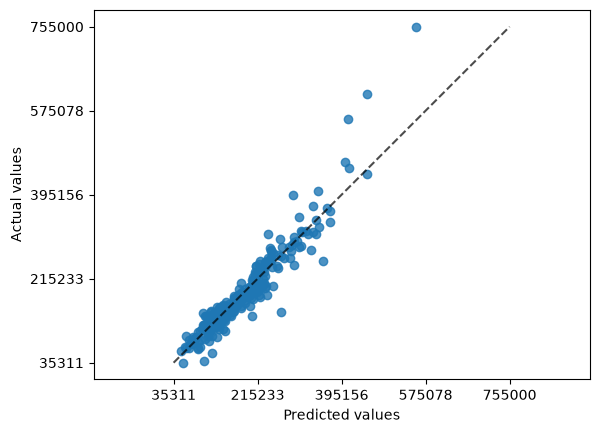

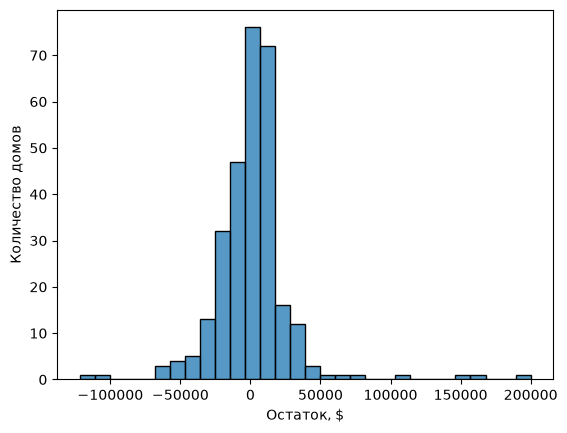

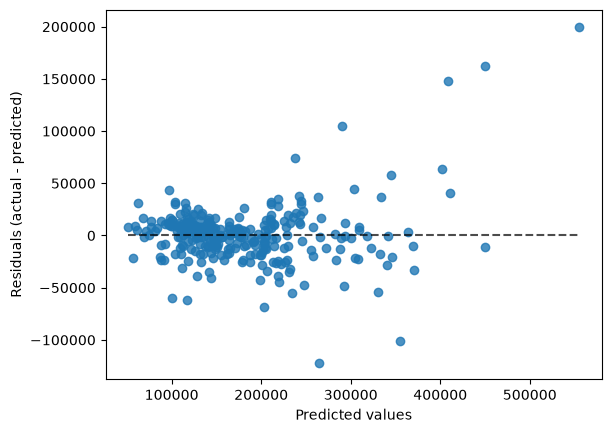

In [37]:
def show_prediction_errors(y_true, y_pred):
    residuals = y_true - y_pred
    PredictionErrorDisplay.from_predictions(y_true, y_pred, kind="actual_vs_predicted")
    plt.show()

    sb.histplot(x=residuals, bins=30).set(xlabel="Остаток, $", ylabel="Количество домов")
    plt.show()

    PredictionErrorDisplay.from_predictions(y_true, y_pred, kind="residual_vs_predicted")
    plt.show()

show_prediction_errors(Y_val, Y_pred)

Рассматриваем десять домов с наибольшей абсолютной ошибкой.

In [35]:
def show_largest_errors(X, y_true, y_pred):
    residuals = y_true - y_pred
    errors = X.copy()
    errors["Id"] = df.loc[X.index, "Id"]
    errors["SalePrice"] = y_true
    errors["PredictedPrice"] = y_pred
    errors["Residual"] = residuals
    errors["AbsoluteError"] = residuals.abs()

    worst_houses = errors.nlargest(10, "AbsoluteError")

    display(
        worst_houses[
            [
                "Id",
                "SalePrice",
                "PredictedPrice",
                "Residual",
                "AbsoluteError",
                "OverallQual",
                "GrLivArea",
                "YearBuilt",
                "Neighborhood",
            ]
        ]
    )
    return errors

errors = show_largest_errors(X_val, Y_val, Y_pred)

,Id,SalePrice,PredictedPrice,Residual,AbsoluteError,OverallQual,GrLivArea,YearBuilt,Neighborhood
691,692,755000,555040.580590,199959.419410,199959.419410,10,4316,1994,NoRidge
898,899,611657,449640.957302,162016.042698,162016.042698,9,2364,2009,NridgHt
1046,1047,556581,408809.317792,147771.682208,147771.682208,9,2868,2005,StoneBr
588,589,143000,264826.105528,-121826.105528,121826.105528,5,1473,1968,ClearCr
774,775,395000,290217.899168,104782.100832,104782.100832,8,1973,2006,NridgHt
581,582,253293,354606.885973,-101313.885973,101313.885973,8,2042,2008,NridgHt
218,219,311500,237374.057364,74125.942636,74125.942636,7,1954,1939,Crawfor
628,629,135000,203068.238061,-68068.238061,68068.238061,5,2080,1969,NAmes
1243,1244,465000,401403.579772,63596.420228,63596.420228,10,2076,2006,NridgHt
812,813,55993,117630.239761,-61637.239761,61637.239761,5,1044,1952,IDOTRR


## Выводы

На holdout получены MAE ≈ $17 161, RMSE ≈ $28 359,
RMSLE ≈ 0,146 и R² ≈ 0,895.

Крупнейшие недооценки относятся к дорогим домам, слабо представленным
в обучающей выборке. Среди крупных ошибок также встречаются редкие условия
продажи. Модели может не хватать подобных примеров и подробностей сделок.

### Random Forest and Gradient boosting
Для дереве и градиентного бустинга убираем скейлинг, в остальном старый препроссесинг (экодинг и Numerical imputation им необходим), Categorical imputation можно убрать, но можно и оставить для консистентности со старыми моделями

Также выбираем попробовать CatBoost, так как много категориальных параметров. Одну предобработку оставляем старую, а для второй дополнительно убираем Categorical imputation (т.к. модель сама с этим справляется)

In [31]:
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from catboost import CatBoostRegressor

numeric_features = X_train.select_dtypes(include="number").columns.drop("MSSubClass").tolist()
categorical_features = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist() + ["MSSubClass"]

rf = RandomForestRegressor(max_features=1/3, bootstrap=True, n_jobs=-1, random_state=0)
gb = GradientBoostingRegressor(random_state=0)
cb = CatBoostRegressor(random_seed=0, verbose=False)
cb_native = CatBoostRegressor(
    cat_features=tuple(categorical_features), random_seed=0, verbose=False
)

preprocess_without_scaler = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="NA")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_features),
])
preprocess_w_one_hot = make_preprocess(X_train)

preprocess_without_one_hot = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), numeric_features),
    ("cat", SimpleImputer(strategy="constant", fill_value="NA"), categorical_features),
], verbose_feature_names_out=False).set_output(transform="pandas")

cases = [
    (preprocess_without_scaler, rf),
    (preprocess_without_scaler, gb),
    (preprocess_w_one_hot, cb),
    (preprocess_without_one_hot, cb_native),
]

### Optuna: главное в этой ячейке

Optuna с TPE использует результаты предыдущих попыток, чтобы выбирать следующие комбинации в пределах заданного бюджета (N_TRIALS)

- `objective(trial)` — наша функция одной попытки: выбирает параметры, оценивает модель через CV и возвращает средний RMSE.
- `trial.suggest_categorical(...)` выбирает значение из списка; `suggest_int(...)` — целое число из диапазона; `suggest_float(...)` — дробное. `log=True` задаёт логарифмическую шкалу поиска.
- `optuna.create_study(...)` создаёт отдельный поиск. `direction='minimize'` означает, что меньший RMSE лучше. `TPESampler(seed=0)` выбирает следующие комбинации с учётом прошлых результатов; `seed` фиксирует случайность этого выбора.
- `study.optimize(objective, n_trials=N_TRIALS)` запускает попытки. 
`N_TRIALS` задаёт число проверяемых комбинаций **для каждой пары цикла. 
Передаём саму функцию `objective`, без скобок. Optuna сама вызывает `objective(trial)` для каждой попытки.
- `trial.set_user_attr('cv_results', ...)` сохраняет рассчитанные нами метрики и время обучения вместе с попыткой.
- `study.best_params` — параметры лучшей попытки; `study.best_value` — её средний CV RMSE. Эти значения читаем без `()`.
- `study.best_trial.user_attrs['cv_results']` — сохранённые метрики лучшей попытки для итоговой таблицы.


In [ ]:
import optuna
from sklearn.base import clone
from sklearn.model_selection import cross_validate

N_TRIALS = 20
rows = []
studies = {}

for prep, model in cases:
    name = type(model).__name__
    if isinstance(model, CatBoostRegressor):
        name += " + one-hot" if prep is preprocess_w_one_hot else " + native"

    def objective(trial):
        if isinstance(model, RandomForestRegressor):
            params = {
                "n_estimators": trial.suggest_categorical("n_estimators", [200, 300, 600]),
                "max_depth": trial.suggest_categorical("max_depth", [None, 8, 16]),
                "min_samples_leaf": trial.suggest_categorical("min_samples_leaf", [1, 3, 5, 10]),
            }
        elif isinstance(model, GradientBoostingRegressor):
            params = {
                "n_estimators": trial.suggest_categorical("n_estimators", [100, 300, 600, 1000]),
                "learning_rate": trial.suggest_float("learning_rate", 0.03, 0.1, log=True),
                "max_depth": trial.suggest_int("max_depth", 2, 4),
                "min_samples_leaf": trial.suggest_categorical("min_samples_leaf", [1, 5, 10, 20]),
            }
        else:  # CatBoost
            params = {
                "n_estimators": trial.suggest_categorical("n_estimators", [300, 600, 1000, 1500]),
                "learning_rate": trial.suggest_float("learning_rate", 0.03, 0.1, log=True),
                "max_depth": trial.suggest_int("max_depth", 4, 8),
                "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1.0, 10.0, log=True),
            }
        pipeline = Pipeline([("prep", prep), ("model", clone(model).set_params(**params))]) #Заменяются только параметры из params, остальные остается как в инициализации
        scores = cross_validate(
            pipeline, X_train, Y_train,
            cv=cv, scoring=scoring, error_score="raise",
        )
        trial.set_user_attr("cv_results", {
            **{f"mean_{key}": float(value.mean()) for key, value in scores.items()},
            **{f"std_{key}": float(value.std()) for key, value in scores.items()},
        })
        return float(-scores["test_RMSE"].mean())

    study = optuna.create_study(
        direction="minimize", sampler=optuna.samplers.TPESampler(seed=0),
    )
    study.optimize(objective, n_trials=N_TRIALS)
    studies[name] = study #В словаре сохраняется отдельный поиск для каждого варианта модели
    rows.append({
        "Model": name, "params": study.best_params,
        **study.best_trial.user_attrs["cv_results"],
    })

columns = [
    "Model", "mean_test_MAE", "std_test_MAE", "mean_test_RMSE", "std_test_RMSE",
    "mean_test_R2", "std_test_R2", "mean_fit_time", "std_fit_time", "params",
]
comparison_results = pd.DataFrame(rows).reindex(columns=columns)
comparison_results[["mean_test_MAE", "mean_test_RMSE"]] *= -1
comparison_results = comparison_results.sort_values("mean_test_RMSE").reset_index(drop=True)
with pd.option_context("display.max_columns", None, "display.max_colwidth", None):
    display(comparison_results.round(3))

/Users/maksim/Library/Python/3.14/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-11-12 22:02:42,134] A new study created in memory with name: no-name-abf12873-0e6c-46e6-8f4a-acb02c2ae581
[I 2026-11-12 22:02:43,331] Trial 0 finished with value: 30208.00847441848 and parameters: {'n_estimators': 300, 'max_depth': 16, 'min_samples_leaf': 5}. Best is trial 0 with value: 30208.00847441848.
[I 2026-11-12 22:02:44,060] Trial 1 finished with value: 31719.350227037172 and parameters: {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 10}. Best is trial 0 with value: 30208.00847441848.
[I 2026-11-12 22:02:44,965] Trial 2 finished with value: 29814.600270922372 and parameters: {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 3}. Best is trial 2 with value: 29814.600270922372.
[I 2026-11-

,Model,mean_test_MAE,std_test_MAE,mean_test_RMSE,std_test_RMSE,mean_test_R2,std_test_R2,mean_fit_time,std_fit_time,params
0,CatBoostRegressor + one-hot,14373.399,2126.105,24656.418,6305.901,0.892,0.048,0.778,0.029,"{'n_estimators': 1500, 'learning_rate': 0.0311296199225486, 'max_depth': 4, 'l2_leaf_reg': 1.1279295874015347}"
1,CatBoostRegressor + native,15002.770,2003.351,25085.113,5574.813,0.888,0.046,6.828,0.018,"{'n_estimators': 1500, 'learning_rate': 0.030237796193640348, 'max_depth': 5, 'l2_leaf_reg': 1.3292360456250623}"
2,GradientBoostingRegressor,15884.742,1906.216,26652.034,5868.072,0.874,0.049,0.952,0.004,"{'n_estimators': 600, 'learning_rate': 0.048887932870702415, 'max_depth': 2, 'min_samples_leaf': 1}"
3,RandomForestRegressor,17343.786,1755.162,29197.662,6113.049,0.850,0.055,0.313,0.006,"{'n_estimators': 300, 'max_depth': 16, 'min_samples_leaf': 1}"


Результаты прошлых моделей:
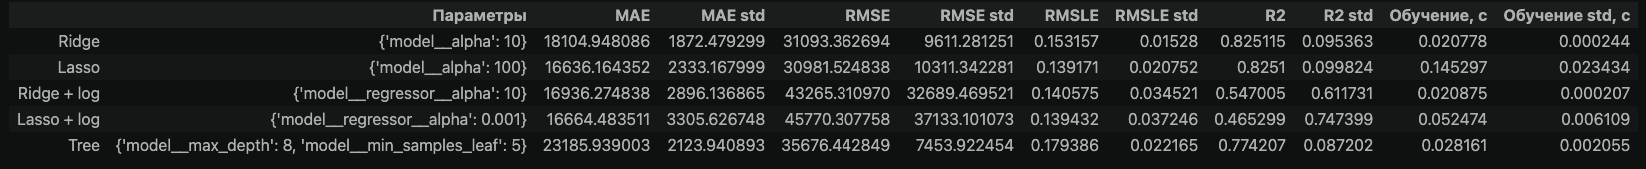

Вывод - некоторые гиперпараметры на границах или близко, по хорошему их подвинуть, но не хочу ждать снова 17 минут

### Финальная проверка на holdout

Выбран CatBoost с one-hot по среднему CV RMSE.

In [ ]:
final_model_cb = Pipeline([
    ("prep", preprocess_w_one_hot),
    ("model", cb.set_params(**studies["CatBoostRegressor + one-hot"].best_params)), #распаковываем словарь в именнованые аргументы
])
final_model_cb.fit(X_train, Y_train)
Y_pred_cb = final_model_cb.predict(X_val)

holdout_metrics_cb = pd.Series({
    "MAE": mean_absolute_error(Y_val, Y_pred_cb),
    "RMSE": root_mean_squared_error(Y_val, Y_pred_cb),
    "RMSLE": root_mean_squared_log_error(Y_val, Y_pred_cb),
    "R2": r2_score(Y_val, Y_pred_cb),
}, name="CatBoost + one-hot: holdout")
display(holdout_metrics_cb.to_frame().round(3))

,CatBoost + one-hot: holdout
MAE,15390.105
RMSE,26450.063
RMSLE,0.135
R2,0.909


Для сравнения CV RMSE показал Lasso с `alpha=100` на этой выборке:
MAE: 17161.14877160682
RMSE: 28359.10980773947
RMSLE: 0.1462814420146376
R²: 0.895149295171586

### Переставляем (permutation) значения признаков между объектами
1)Посчитать permutation importance финальной модели.
2)Сравнить её со встроенной важностью CatBoost.
3)Объединить важности one-hot колонок по исходным признакам.

1. permutation_importance(...) — проверяем зависимость модели от признаков.
По очереди проверяет все столбцы переданного X_val.
n_repeats=5 — пять перемешиваний каждого признака;
Для каждого исходного столбца функция перемешивает значения и проверяет прогнозы. Обучение заново не происходит.

2. Ввстроенная важность CatBoost
Это другой способ оценки, который предоставляет сам CatBoost через feature_importances_.  Он анализирует обученные деревья: насколько с использованием признака связаны изменения предсказаний. Затем нормирует полученные важности так, чтобы их сумма по всем признакам была равна 100. 
Поэтому значение 12 означает 12 баллов из общей суммы 100 по внутренней оценке CatBoost. Это не RMSE, не изменение RMSE и не снижение ошибки на 12%.

In [ ]:
from sklearn.inspection import permutation_importance

# ===== 1. PERMUTATION IMPORTANCE: перемешиваем признаки и измеряем рост RMSE =====
perm = permutation_importance(
    final_model_cb, X_val, Y_val,
    scoring="neg_root_mean_squared_error", n_repeats=5, random_state=0,
)
# КОНЕЦ PERMUTATION.

# ===== 2. ВСТРОЕННАЯ ВАЖНОСТЬ CATBOOST: отдельный результат модели =====
encoder = final_model_cb.named_steps["prep"].named_transformers_["cat"].named_steps["encoder"]
original_features = numeric_features + np.repeat(
    categorical_features, [len(values) for values in encoder.categories_]
).tolist()
tree_importance = pd.Series(
    final_model_cb.named_steps["model"].feature_importances_, index=original_features
).groupby(level=0).sum()
# КОНЕЦ ВСТРОЕННОЙ ВАЖНОСТИ.

# ===== 3. СРАВНЕНИЕ: 
importance_comparison = pd.DataFrame({
    "Permutation: рост RMSE": perm.importances_mean,
    "Permutation STD": perm.importances_std,
    "CatBoost importance": tree_importance,
}, index=X_val.columns).sort_values("Permutation: рост RMSE", ascending=False)
display(importance_comparison.head(15).round(3))

,Permutation: рост RMSE,Permutation STD,CatBoost importance
OverallQual,15030.309,1121.586,22.811
GrLivArea,13727.491,306.774,14.612
TotalBsmtSF,4482.121,355.359,6.013
BsmtFinSF1,2691.151,327.090,4.689
GarageCars,2415.424,143.369,4.519
2ndFlrSF,2195.083,141.506,2.314
1stFlrSF,2042.166,146.334,3.357
LotArea,1824.555,226.263,3.356
BsmtQual,1170.906,277.135,3.683
Neighborhood,1141.732,191.124,1.545


Напрямую число из одного столбца с числом из другого не сравниваем. Сравниваем признаки внутри каждого столбца, а потом смотрим, согласны ли методы.
Вывод: оба подхода подтверждают важность качества дома и жилой площади; среди других существенных характеристик выделяются подвал и гараж.

### Анализ крупных ошибок финальной модели

In [43]:
errors_cb = show_largest_errors(X_val, Y_val, Y_pred_cb)

,Id,SalePrice,PredictedPrice,Residual,AbsoluteError,OverallQual,GrLivArea,YearBuilt,Neighborhood
691,692,755000,557514.290264,197485.709736,197485.709736,10,4316,1994,NoRidge
898,899,611657,465010.554214,146646.445786,146646.445786,9,2364,2009,NridgHt
581,582,253293,376059.581568,-122766.581568,122766.581568,8,2042,2008,NridgHt
774,775,395000,274040.026879,120959.973121,120959.973121,8,1973,2006,NridgHt
1046,1047,556581,441852.638057,114728.361943,114728.361943,9,2868,2005,StoneBr
588,589,143000,232565.165327,-89565.165327,89565.165327,5,1473,1968,ClearCr
261,262,276000,359861.136608,-83861.136608,83861.136608,8,2574,2007,CollgCr
218,219,311500,238008.591221,73491.408779,73491.408779,7,1954,1939,Crawfor
1243,1244,465000,409989.635004,55010.364996,55010.364996,10,2076,2006,NridgHt
1024,1025,287000,340588.361069,-53588.361069,53588.361069,8,2898,1976,Timber


Нет особой разницы с тем что было у худщих результатов - Восемь из десяти домов повторяются в обоих списках. Для шести из них ошибка уменьшилась, для двух — выросла.
При этом на всём holdout качество улучшилось: RMSE снизился с 28 359 до 26 450 — примерно на 6,7%, MAE — с 17 161 до 15 390 — на 10,3%